# Прогнозирование отмен бронирований: бейзлайн

## Задача и метрика

Построим простую модель для классификации бронирований и оценки риска отмены. Используем данные, известные на момент бронирования. Основная метрика — ROC-AUC. Для сравнения возьмём константную модель с наиболее частым ответом.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 1441001
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("../data/hotel_bookings.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## Признаки

Используем параметры запрошенного бронирования, дату планового заезда, канал продаж, тип депозита и историю гостя. Предполагаем, что выбранные значения известны при оформлении.

reservation_status и reservation_status_date раскрывают итог и исключены из признаков. Также исключаем характеристики номера, которые могут измениться после бронирования: время ожидания, парковку и специальные запросы. Коды агента и компании для упрощения опускаем. Для использования эффектов сезонности убираем год и неделю, оставляем только месяц и день, дальше года будут меняться. Месяц кодируем one-hot, день месяца оставляем числовым, как в простом бейзлайне.

Аномальные значения и возможные дубли сохраняем, как в EDA, не удалось точно удостовериться в их происхождении. Если одинаковые записи попадут в разные выборки, оценка качества может оказаться завышенной.

In [2]:
numeric_features = [
    "lead_time", "arrival_date_day_of_month", "stays_in_weekend_nights",
    "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "adr",
]
categorical_features = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment",
    "distribution_channel", "reserved_room_type", "deposit_type",
    "customer_type",
]
X = df[numeric_features + categorical_features]
y = df["is_canceled"]

## Train / validation / test

Делим строки случайно: 60% на обучение, 20% на валидацию и 20% на тест с сохранением доли отменённых бронирований. На валидации выбираем порог, после этого оцениваем результат на тесте.

In [3]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE,
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev,
    random_state=RANDOM_STATE,
)

pd.DataFrame({
    "Split": ["train", "validation", "test"],
    "Rows": [len(y_train), len(y_valid), len(y_test)],
    "Cancellation rate": [y_train.mean(), y_valid.mean(), y_test.mean()],
}).set_index("Split")

,Rows,Cancellation rate
Split,,
train,71634,0.370411
validation,23878,0.370425
test,23878,0.370425


## Предобработка

Числовые пропуски заполняем медианами обучающей выборки. Затем применяем StandardScaler: масштаб признаков влияет на регуляризацию логистической регрессии. Выбросы для этого бейзлайна оставляем без изменений.

Категориальные пропуски обозначаем Missing, а Undefined сохраняем отдельной категорией. Используем OneHotEncoder, поскольку у категорий нет естественного порядка, неизвестные категории кодируются нулями (handle_unknown="ignore").

In [4]:
medians = X_train[numeric_features].median()
scaler = StandardScaler()

train_numeric = scaler.fit_transform(
    X_train[numeric_features].fillna(medians)
)
valid_numeric = scaler.transform(
    X_valid[numeric_features].fillna(medians)
)
test_numeric = scaler.transform(
    X_test[numeric_features].fillna(medians)
)

In [5]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
train_categories = encoder.fit_transform(
    X_train[categorical_features].fillna("Missing")
)
valid_categories = encoder.transform(
    X_valid[categorical_features].fillna("Missing")
)
test_categories = encoder.transform(
    X_test[categorical_features].fillna("Missing")
)

X_train_prepared = np.column_stack([train_numeric, train_categories])
X_valid_prepared = np.column_stack([valid_numeric, valid_categories])
X_test_prepared = np.column_stack([test_numeric, test_categories])
print("Training matrix shape:", X_train_prepared.shape)

Training matrix shape: (71634, 226)


## Обучение моделей

Константа предсказывает наиболее частый обучающий класс. Она не различает бронирования, поэтому её ROC-AUC должен быть 0,5.

Обучаем логистическую регрессию с L2-регуляризацией.

In [6]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_prepared, y_train)

log_reg = LogisticRegression(
    C=1.0, solver="liblinear", max_iter=1000, random_state=RANDOM_STATE,
)
log_reg.fit(X_train_prepared, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1441001
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.

## Порог по accuracy на валидации

Дополнительно проверяем, улучшает ли подбор порога долю правильных ответов. Выбираем порог ближе к 0.5 при прочих равных.

In [7]:
valid_probabilities = log_reg.predict_proba(X_valid_prepared)[:, 1]
thresholds = np.linspace(0, 1, 101)
valid_accuracy = []

for threshold in thresholds:
    valid_predictions = (valid_probabilities >= threshold).astype(int)
    valid_accuracy.append(accuracy_score(y_valid, valid_predictions))

threshold_results = pd.DataFrame({
    "Threshold": thresholds,
    "Accuracy": valid_accuracy,
    "Diff": abs(thresholds - 0.5),
})
best = threshold_results.sort_values(
    ["Accuracy", "Diff"], ascending=[False, True],
).iloc[0]
best_threshold = best["Threshold"]
print(f"Best threshold: {best_threshold:.2f}")
print(f"Accuracy on validation: {best['Accuracy']:.4f}")

Best threshold: 0.47
Accuracy on validation: 0.7849


## Оценка на тесте

Сравниваем константу и одну логистическую регрессию при пороге 0,5 и выбранном пороге.

ROC-AUC оценивает ранжирование; PR-AUC (AP) считаем через average_precision_score, как в лекциях 5–6. AP отличается от площади методом трапеций.

Accuracy — доля правильных ответов по обоим классам.

Precision — доля фактических отмен среди предсказанных; recall — доля найденных отмен среди всех отмен.

Если нет предсказанных отмен, precision не определён; в таблице условно ставим 0 (zero_division=0). Изменение порога влияет на accuracy, precision и recall, но не на ROC-AUC и AP.

In [8]:
def classification_metrics(target, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(target, probabilities),
        "Accuracy": accuracy_score(target, predictions),
        "Precision": precision_score(target, predictions, zero_division=0),
        "Recall": recall_score(target, predictions),
        "PR-AUC (AP)": average_precision_score(target, probabilities),
    }


dummy_probabilities = dummy.predict_proba(X_test_prepared)[:, 1]
test_probabilities = log_reg.predict_proba(X_test_prepared)[:, 1]
results = pd.DataFrame({
    "Dummy": classification_metrics(y_test, dummy_probabilities),
    "LogReg: 0.5": classification_metrics(y_test, test_probabilities),
    f"LogReg: {best_threshold:.2f}": classification_metrics(
        y_test, test_probabilities, best_threshold,
    ),
}).T
results.round(4)

,ROC-AUC,Accuracy,Precision,Recall,PR-AUC (AP)
Dummy,0.5000,0.6296,0.0000,0.0000,0.3704
LogReg: 0.5,0.8586,0.7876,0.7998,0.5691,0.8178
LogReg: 0.47,0.8586,0.7886,0.7802,0.5975,0.8178


### PR-кривая

По оси X — recall, по оси Y — precision. Пунктир показывает долю отмен и служит ориентиром для случайного ранжирования.

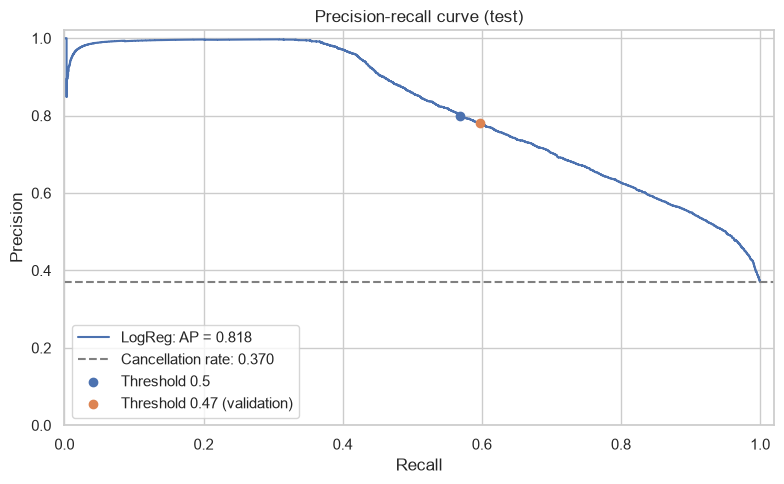

In [9]:
precision, recall, _ = precision_recall_curve(y_test, test_probabilities)
ap = average_precision_score(y_test, test_probabilities)
plot_thresholds = [
    (0.5, "Threshold 0.5"),
    (best_threshold, f"Threshold {best_threshold:.2f} (validation)"),
]

plt.figure()
plt.step(recall, precision, where="post", label=f"LogReg: AP = {ap:.3f}")
plt.axhline(
    y_test.mean(), color="gray", linestyle="--",
    label=f"Cancellation rate: {y_test.mean():.3f}",
)
for threshold, label in plot_thresholds:
    predictions = (test_probabilities >= threshold).astype(int)
    plt.scatter(
        recall_score(y_test, predictions),
        precision_score(y_test, predictions, zero_division=0),
        label=label, zorder=3,
    )
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curve (test)")
plt.xlim(0, 1.02)
plt.ylim(0, 1.02)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

### ROC-кривая
FPR-TPR. Следим за способностью модели верно различать категории.

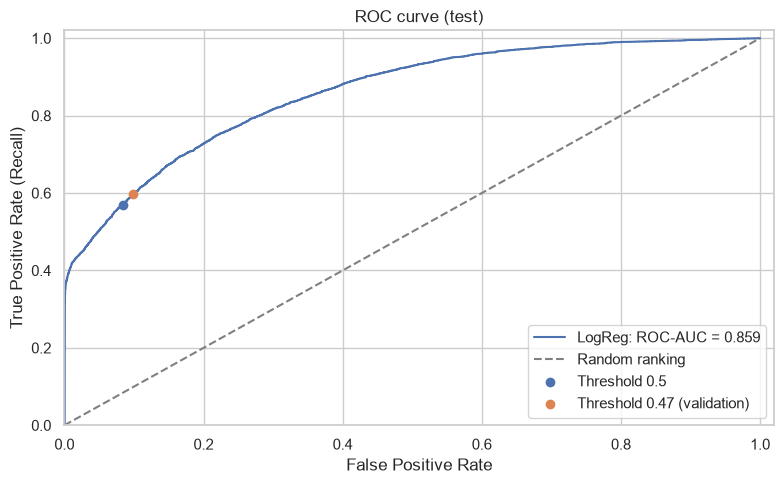

In [10]:
fpr, tpr, _ = roc_curve(y_test, test_probabilities)
roc_auc = roc_auc_score(y_test, test_probabilities)

plt.figure()
plt.plot(fpr, tpr, label=f"LogReg: ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
for threshold, label in plot_thresholds:
    predictions = (test_probabilities >= threshold).astype(int)
    point_fpr = predictions[y_test.to_numpy() == 0].mean()
    plt.scatter(
        point_fpr, recall_score(y_test, predictions), label=label, zorder=3,
    )
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curve (test)")
plt.xlim(0, 1.02)
plt.ylim(0, 1.02)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Итого

Логистическая регрессия получила на тесте ROC-AUC 0,8586 и AP 0,8178 против 0,5 и 0,3704 у константы. Accuracy модели при пороге 0,5 — 0,7876, константы — 0,6296.

На валидации выбран порог 0,47. На тесте accuracy выросла до 0,7886, recall — с 0,5691 до 0,5975, а precision снизился с 0,7998 до 0,7802.